In [ ]:
%pip install -q scikit-learn==1.5.2
%pip install -q tsururu==1.1.0
%pip install chronos-forecasting

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
chronos-forecasting 2.2.2 requires scikit-learn<2,>=1.6.0, but you have scikit-learn 1.5.2 which is incompatible.
shap 0.51.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
umap-learn 0.5.12 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.
hdbscan 0.8.42 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.
  Using cached scikit_learn-1.8.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (11 kB)
Using cached scikit_learn-1.8.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (8.9 MB)
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.5.2
    Uninstalling scikit-learn-1.5.2:
      Successfully uninstalled scikit-learn-1.5.2
ERROR: pip's dependency resolver does not cu

In [ ]:
import logging

logger = logging.getLogger(__name__)
import sys

c_handler = logging.StreamHandler(sys.stdout)
logger.addHandler(c_handler)
logging.basicConfig(level=logging.INFO, force=True)

import random
import warnings
from datetime import datetime
from typing import Any

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import torch
import torch.nn as nn
from chronos import BaseChronosPipeline
from plotly.subplots import make_subplots
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import (
    MinMaxScaler,
    PowerTransformer,
    RobustScaler,
    StandardScaler,
)
from torch.nn import Module
from tqdm.notebook import tqdm

from tsururu.dataset import Pipeline, TSDataset
from tsururu.model_training.trainer import DLTrainer, MLTrainer
from tsururu.model_training.validator import KFoldCrossValidator, HoldOutValidator
from tsururu.models.boost import CatBoost
from tsururu.strategies import RecursiveStrategy

warnings.filterwarnings("ignore")

In [ ]:
def choose_device():
    if torch.cuda.is_available():
        device = torch.device("cuda")
        print("Using GPU")
    elif torch.backends.mps.is_available():
        device = torch.device("mps")
        print("Using MPS")
    else:
        device = torch.device("cpu")
        print("Using CPU")
    return device


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [ ]:
DEVICE = choose_device()
HORIZON = 36
HISTORY = 52

Using GPU


In [ ]:
seed_everything()

# Dataset

Возьмем данные Tourism Monthly Dataset (https://zenodo.org/records/4656096).

In [ ]:
def convert_tsf_to_dataframe(
    full_file_path_and_name: str,
    replace_missing_vals_with: Any = "NaN",
    value_column_name: str = "series_value",
) -> tuple[pd.DataFrame, str, int, str, str]:
    col_names = []
    col_types = []
    all_data = {}
    all_series = []
    frequency = None
    forecast_horizon = None
    contain_missing_values = None
    contain_equal_length = None
    data_started = False

    with open(full_file_path_and_name, "r", encoding="cp1252") as file:
        for line in file:
            line = line.strip()
            if not line:
                continue
            if line.startswith("@"):
                if line.startswith("@data"):
                    data_started = True
                    for col in col_names:
                        all_data[col] = []
                else:
                    parts = line.split(" ")
                    if line.startswith("@attribute"):
                        col_names.append(parts[1])
                        col_types.append(parts[2])
                    elif line.startswith("@frequency"):
                        frequency = parts[1]
                    elif line.startswith("@horizon"):
                        forecast_horizon = int(parts[1])
                    elif line.startswith("@missing"):
                        contain_missing_values = parts[1].lower() in (
                            "y",
                            "yes",
                            "t",
                            "true",
                            "on",
                            "1",
                        )
                    elif line.startswith("@equallength"):
                        contain_equal_length = parts[1].lower() in (
                            "y",
                            "yes",
                            "t",
                            "true",
                            "on",
                            "1",
                        )
            elif not line.startswith("#") and data_started:
                parts = line.split(":")
                series_vals = parts[-1].split(",")
                numeric_series = [
                    replace_missing_vals_with if val == "?" else float(val) for val in series_vals
                ]
                all_series.append(pd.Series(numeric_series).array)
                for i in range(len(col_names)):
                    if col_types[i] == "numeric":
                        all_data[col_names[i]].append(int(parts[i]))
                    elif col_types[i] == "string":
                        all_data[col_names[i]].append(parts[i])
                    elif col_types[i] == "date":
                        all_data[col_names[i]].append(
                            datetime.strptime(parts[i], "%Y-%m-%d %H-%M-%S")
                        )

    all_data[value_column_name] = all_series
    loaded_data = pd.DataFrame(all_data)
    return loaded_data, frequency, forecast_horizon, contain_missing_values, contain_equal_length


def date_to_daterange(x: pd.Series, freq: str) -> pd.Series:
    return pd.Series(pd.date_range(start=x.iloc[0], periods=len(x), freq=freq))


def convert_tsf_to_multivariate_or_standard_format(
    tsf_data_path: str,
    target_column: str = "series_value",
    date_from_column: str = "start_timestamp",
    id_column: str = "series_name",
    format: str = "multivariate",
) -> pd.DataFrame:

    FREQ_MAP = {
        "monthly": "MS",
        "10_minutes": "10min",
        "half_hourly": "30min",
        "minutely": "1min",
        "daily": "D",
        "weekly": "7D",
        "yearly": "YS",
        "quarterly": "QS",
        "hourly": "H",
    }

    tsf_df, freq = convert_tsf_to_dataframe(tsf_data_path)[:2]
    tsf_df = tsf_df.explode(target_column)
    tsf_df["date"] = (
        tsf_df.groupby(id_column, sort=False)[date_from_column]
        .apply(lambda x: date_to_daterange(x, FREQ_MAP[freq]))
        .values
    )
    tsf_df = tsf_df.drop(columns=date_from_column)
    tsf_df = tsf_df.rename(columns={id_column: "id", target_column: "value"}).reset_index(
        drop=True
    )
    ids2num = dict(zip(tsf_df["id"].unique(), np.arange(tsf_df["id"].nunique())))
    tsf_df["id"] = tsf_df["id"].map(ids2num)

    if format == "standard":
        return tsf_df
    return pd.pivot_table(tsf_df, values="value", index="date", columns="id")

In [ ]:
df = convert_tsf_to_multivariate_or_standard_format('tourism_monthly_dataset.tsf', format="standard")
df["value"] = df["value"].astype("float")
df.head()

,id,value,date
0,0,1149.8700,1979-01-01
1,0,1053.8002,1979-02-01
2,0,1388.8798,1979-03-01
3,0,1783.3702,1979-04-01
4,0,1921.0252,1979-05-01


In [ ]:
fig = go.Figure()
for i in df["id"].unique():
    fig.add_trace(
        go.Scatter(x=df[df["id"] == i]["date"], y=df[df["id"] == i]["value"], name=str(i))
    )
fig.update_layout(title="Tourism Monthly Dataset", xaxis_title="Date", yaxis_title="Value")
fig.show()

# Preprocessing

Методы предобработки временных рядов помогают стабилизировать данные, удалить тренды и сезонность, и привести значения к сопоставимому диапазону.

__Давайте на примере одного ряда посмотрим, как они работают.__

In [13]:
random_series = 33
random_series = df[df["id"] == random_series]

train_size = len(random_series) - HORIZON
train_split_date = np.sort(random_series["date"])[train_size]

train_data = random_series[random_series["date"] < train_split_date]
test_data = random_series[random_series["date"] >= train_split_date]

`Логарифмирование / Box-Cox / Yeo-Johnson`

Эти методы используются, чтобы стабилизировать дисперсию. Особенно полезны при наличии мультипликативных эффектов.

- Логарифмирование и Box-Cox подходит только для положительных значений.
- Yeo-Johnson может применяться при отрицательных значениях.

__Box-Cox__:

$$ y' = \frac{y^\lambda - 1}{\lambda} \text{, если } \lambda \neq 0$$
$$ y' = \log(y) \text{, если } \lambda = 0$$

__Yeo-Johnson__:
$$ y' = \begin{cases}
\frac{((y + 1)^\lambda - 1)}{\lambda} \text{, если } y \geq 0 \text{ и } \lambda \neq 0\\
\log(y + 1) \text{, если } y \geq 0 \text{ и } \lambda = 0\\
\frac{-((-y + 1)^{2 - \lambda} - 1)}{2 - \lambda} \text{, если } y < 0 \text{ и } \lambda \neq 2\\
-\log(-y + 1) \text{, если } y < 0 \text{ и } \lambda = 2
\end{cases}$$

На практике чаще используют простое логарифмирование, так как с более сложными методами возникают с подбором параметров.

Обратите так же внимание, что при использовании подобных трансформаций обратное преобразование точечного прогноза не даёт среднее значение прогностического распределения. На практике это значение обычно соответствует медиане распределения и иногда это необходимо учитывать и корректировать.

__Обратное преобразование для Box-Cox, при котором мы учитываем смещение (bias adjusted)__:

$$ y = \begin{cases}
(\lambda y' + 1)^{\frac{1}{\lambda}} \left[1 + \dfrac{\sigma^2_h(1-\lambda)}{2(\lambda y' + 1)^2} \right] \text{, если } \lambda \neq 0\\
\exp(y') \left[ 1 + \dfrac{\sigma^2_h}{2} \right] \text{, если } \lambda = 0
\end{cases}$$

__Пример того, насколько могут различаться скорректированные и некорректированные обратные преобразования__:

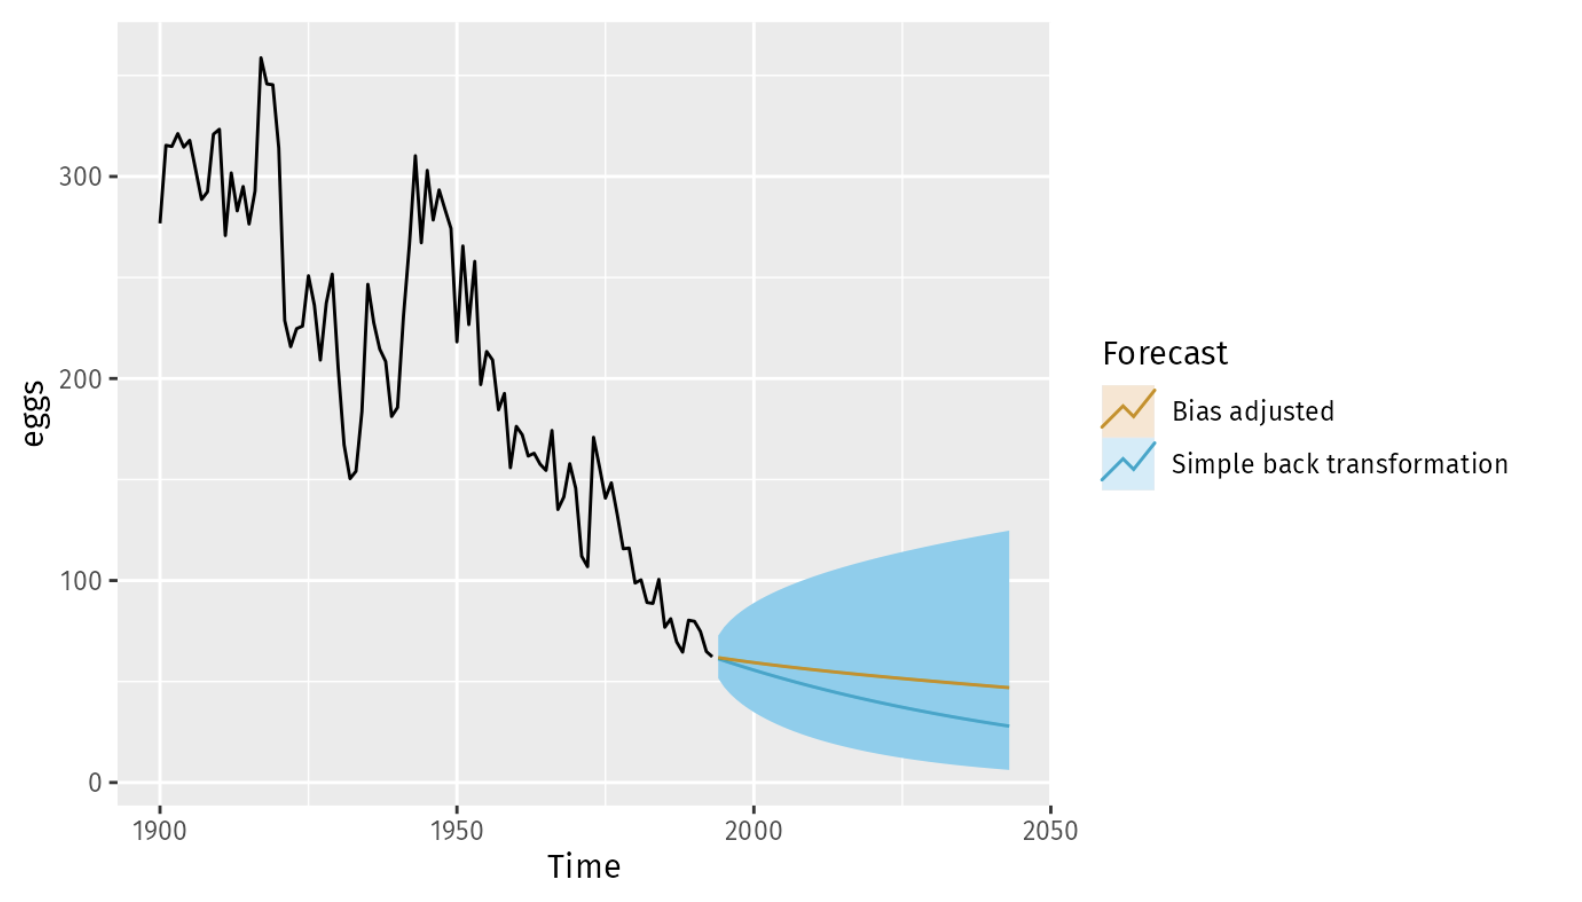

Оба метода есть в sklearn: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PowerTransformer.html

Однако обратите внимание, что обратное преобразование там смещенное.

In [14]:
# Logarithmic transformation
train_data["log_value"] = np.log1p(train_data["value"])
test_data["log_value"] = np.log1p(test_data["value"])

# Box-Cox transformation
pt = PowerTransformer(method="box-cox")
train_data["boxcox_value"] = pt.fit_transform(train_data[["value"]])
test_data["boxcox_value"] = pt.transform(test_data[["value"]])

# Yeo-Johnson transformation
pt = PowerTransformer(method="yeo-johnson")
train_data["yeojohnson_value"] = pt.fit_transform(train_data[["value"]])
test_data["yeojohnson_value"] = pt.transform(test_data[["value"]])

In [15]:
fig = make_subplots(cols=2, subplot_titles=("Оригинальный ряд", "Преобразования"))
for dataset, name in zip([train_data, test_data], ["train", "test"]):
    fig.add_trace(
        go.Scatter(x=dataset["date"], y=dataset["value"], name=name),
        row=1, col=1
    )
for transformer in ["log_value", "boxcox_value", "yeojohnson_value"]:
    for dataset, prefix in zip([train_data, test_data], ["train", "test"]):
        fig.add_trace(
            go.Scatter(x=dataset["date"], y=dataset[transformer], name=f"{prefix}_{transformer}"),
            row=1, col=2
        )
fig.update_layout(
    title="Преобразования временного ряда",
    xaxis_title="Date",
    yaxis_title="Value",
    showlegend=True
)

fig.show()

`Сезонное и обычное дифференцирование`

Сезонное дифференцирование помогает убрать влияние сезонности, а обычное дифференцирование — тренд.
- Сезонное дифференцирование: $y_t - y_{t-s}$ или $y_t / y_{t-s}$, где $s$ — длина сезона
- Обычное дифференцирование: $y_t - y_{t-1}$ или $y_t / y_{t-1}$

In [16]:
# Seasonal Difference
train_data["seasonal_diff_delta"] = train_data["value"].diff(12)
test_data["seasonal_diff_delta"] = test_data["value"].diff(12)
train_data["seasonal_diff_ratio"] = train_data["value"] / train_data["value"].shift(12)
test_data["seasonal_diff_ratio"] = test_data["value"] / test_data["value"].shift(12)

# Difference
train_data["diff_delta"] = train_data["value"].diff(1)
test_data["diff_delta"] = test_data["value"].diff(1)
train_data["diff_ratio"] = train_data["value"] / train_data["value"].shift(1)
test_data["diff_ratio"] = test_data["value"] / test_data["value"].shift(1)

In [17]:
fig = make_subplots(cols=2, subplot_titles=("Оригинальный ряд", "Разности"))
for dataset, name in zip([train_data, test_data], ["train", "test"]):
    fig.add_trace(
        go.Scatter(x=dataset["date"], y=dataset["value"], name=name),
        row=1, col=1
    )
for transformer in ["seasonal_diff_delta", "diff_delta"]:
    for dataset, prefix in zip([train_data, test_data], ["train", "test"]):
        fig.add_trace(
            go.Scatter(x=dataset["date"], y=dataset[transformer], name=f"{prefix}_{transformer}"),
            row=1, col=2
        )
fig.update_layout(
    title="Разности временного ряда",
    xaxis_title="Date",
    yaxis_title="Value",
    showlegend=True
)
fig.show()

In [18]:
fig = make_subplots(cols=2, subplot_titles=("Оригинальный ряд", "Разности"))
for dataset, name in zip([train_data, test_data], ["train", "test"]):
    fig.add_trace(
        go.Scatter(x=dataset["date"], y=dataset["value"], name=name),
        row=1, col=1
    )
for transformer in ["seasonal_diff_ratio", "diff_ratio"]:
    for dataset, prefix in zip([train_data, test_data], ["train", "test"]):
        fig.add_trace(
            go.Scatter(x=dataset["date"], y=dataset[transformer], name=f"{prefix}_{transformer}"),
            row=1, col=2
        )
fig.update_layout(
    title="Разности временного ряда",
    xaxis_title="Date",
    yaxis_title="Value",
    showlegend=True
)
fig.show()

`StandartScaler, MinMaxScaler, RobustScaler`

Эти методы помогают привести данные к сопоставимому диапазону, что может быть критично для некоторых моделей.

- StandartScaler: $$y' = \frac{y - \mu}{\sigma}$$ где $\mu$ и $\sigma$ — среднее и стандартное отклонение соответственно.
  
- MinMaxScaler: $$y' = \frac{y - min(y)}{max(y) - min(y)}$$
  
- RobustScaler: $$y' = \frac{y - Q1}{Q3 - Q1}$$ где Q1 и Q3 — первый и третий квартили соответственно.

In [19]:
# Standard Scaler
scaler = StandardScaler()
train_data["scaled_value"] = scaler.fit_transform(train_data[["value"]])
test_data["scaled_value"] = scaler.transform(test_data[["value"]])

# MinMax Scaler
scaler = MinMaxScaler()
train_data["minmax_scaled_value"] = scaler.fit_transform(train_data[["value"]])
test_data["minmax_scaled_value"] = scaler.transform(test_data[["value"]])

# Robust Scaler
scaler = RobustScaler()
train_data["robust_scaled_value"] = scaler.fit_transform(train_data[["value"]])
test_data["robust_scaled_value"] = scaler.transform(test_data[["value"]])

In [20]:
fig = make_subplots(cols=2, subplot_titles=("Оригинальный ряд", "Ряды после скейлингов"))
for dataset, name in zip([train_data, test_data], ["train", "test"]):
    fig.add_trace(
        go.Scatter(x=dataset["date"], y=dataset["value"], name=name),
        row=1, col=1
    )
for transformer in [
    "scaled_value",
    "minmax_scaled_value",
    "robust_scaled_value",
]:
    for dataset, prefix in zip([train_data, test_data], ["train", "test"]):
        fig.add_trace(
            go.Scatter(x=dataset["date"], y=dataset[transformer], name=f"{prefix}_{transformer}"),
            row=1, col=2
        )
fig.update_layout(
    title="Скейлинги временного ряда",
    xaxis_title="Date",
    yaxis_title="Value",
    showlegend=True
)
fig.show()

### Multivariate Time Series: using Tsururu

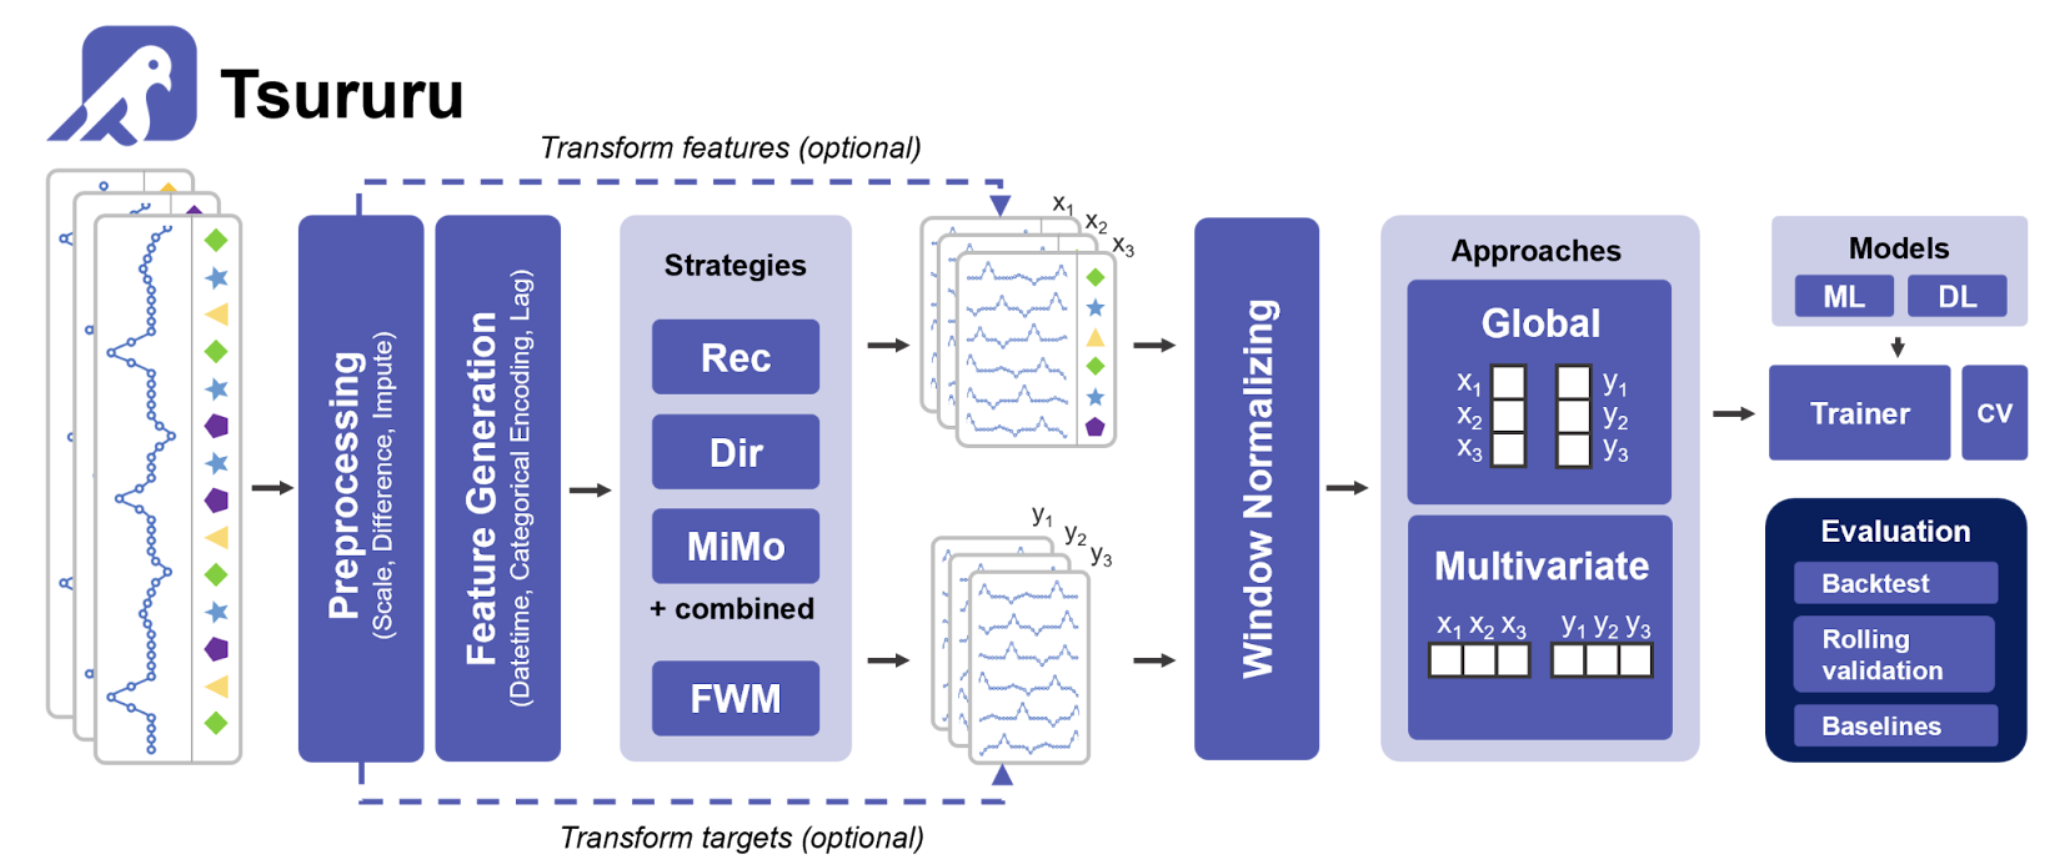

В библиотеке Tsururu реализованы несколько методов предобработки данных, которые позволяют это сделать:
- StandardScalerTransformer
- DifferenceNormalizer
- LastKnownNormalizer

Первые два совпадают с тем, что мы смотрели выше. Просто добавляется возможность указать, __надо ли считать разные ряды за независимые сегменты (например, для целевой переменной) или нет (например, для признаков дат). Также можно указать, нужно ли трансформировать признаки и таргеты или только что-то одно из них.__ `LastKnownNormalizer` работает в окне: мы вычитаем из текущего значения в окне последнее известное значение (или делим на него). Это помогает нам бороться с локальными артефактами.

Если интересно, как это устроено внутри библиотеки, то есть очень подробный туториал о том, как работает пайплайн предобработки и генерации признаков: https://github.com/sb-ai-lab/tsururu/blob/main/examples/Tutorial_3_Transformers_and_Pipeline.ipynb

In [21]:
def analyze_predictions(train_df, test_targets, current_pred, last_points=50):
    train_df = train_df.rename(columns={
        "unique_id": "id",
        "y": "value",
        "ds": "date",
    })

    num_ids = 10
    last_points = 50

    colors = [
        "blue", "green", "orange", "purple", "brown",
        "cyan", "magenta", "olive", "teal", "grey",
    ]

    seed_everything()
    random_ids = np.random.choice(test_targets["id"].unique(), num_ids, replace=False)

    random_mae = mean_absolute_error(
        test_targets.loc[test_targets["id"].isin(random_ids), "value"],
        current_pred.loc[current_pred["id"].isin(random_ids), "value"],
    )
    print(f"random {num_ids} mae: {random_mae}")

    fig = go.Figure()

    for i, _id in enumerate(random_ids):
        color = colors[i % len(colors)]

        train_series = train_df[train_df["id"] == _id]
        train_series = train_series.iloc[-min(len(train_series), last_points):]
        train_values = train_series["value"].tolist()
        n_train = len(train_values)

        test_targets_series = test_targets[test_targets["id"] == _id]
        target_values = test_targets_series["value"].tolist()
        n_test = len(target_values)

        preds_series = current_pred[current_pred["id"] == _id]
        preds_values = preds_series["value"].tolist()

        x_train = np.arange(-n_train, 0)
        x_test = np.arange(0, n_test)
        x_pred = np.arange(0, n_test)

        fig.add_trace(go.Scatter(
            x=x_train,
            y=train_values,
            mode="lines",
            name=f"id {_id} train",
            line=dict(color=color)
        ))

        fig.add_trace(go.Scatter(
            x=x_test,
            y=target_values,
            mode="lines",
            name=f"id {_id} true",
            line=dict(color=color)
        ))

        fig.add_trace(go.Scatter(
            x=x_pred,
            y=preds_values,
            mode="lines",
            name=f"id {_id} pred",
            line=dict(color=color, dash="dash")
        ))

    fig.add_shape(dict(
        type="line",
        x0=0,
        y0=0,
        x1=0,
        y1=1,
        xref="x",
        yref="paper",
        line=dict(color="red", width=4)
    ))

    fig.update_layout(
        title="Predictions vs True Values",
        xaxis_title="Date",
        yaxis_title="Values"
    )

    fig.show()

__Будем использовать неклассическую Global Rec-MIMO стратегию и CatBoost в качестве базовой модели.__

Global-стратегия позволит нам работать с невыровненными рядами.

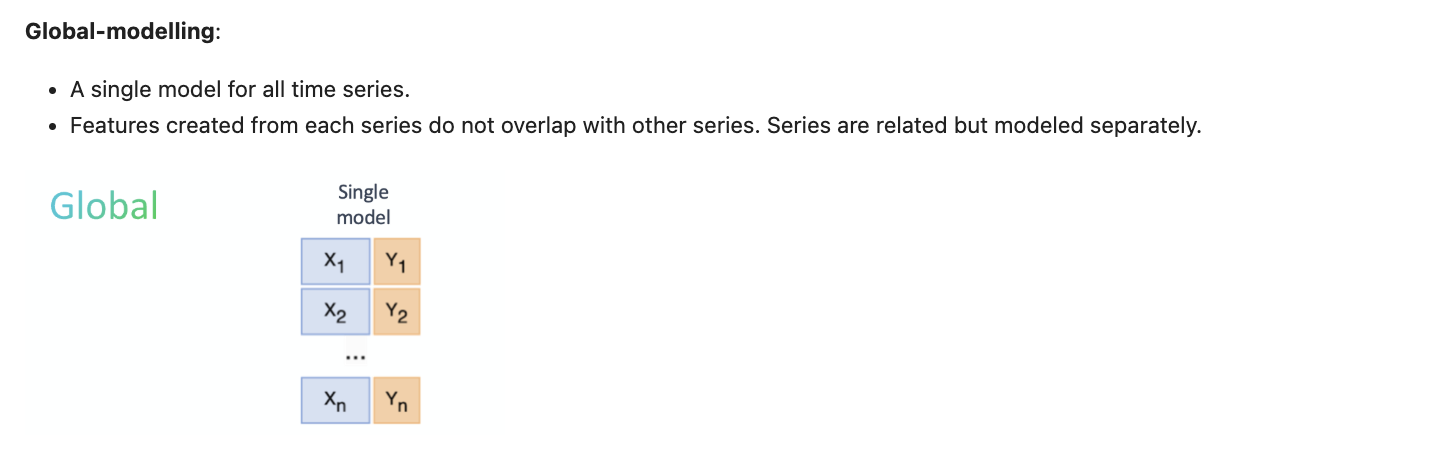

А Rec-MIMO позволит нам получить что-то среднее между быстрой и привычной для классического анализа временных рядов авторегрессионной стратегией и более сложной и привычной для DL multioutput стратегией.

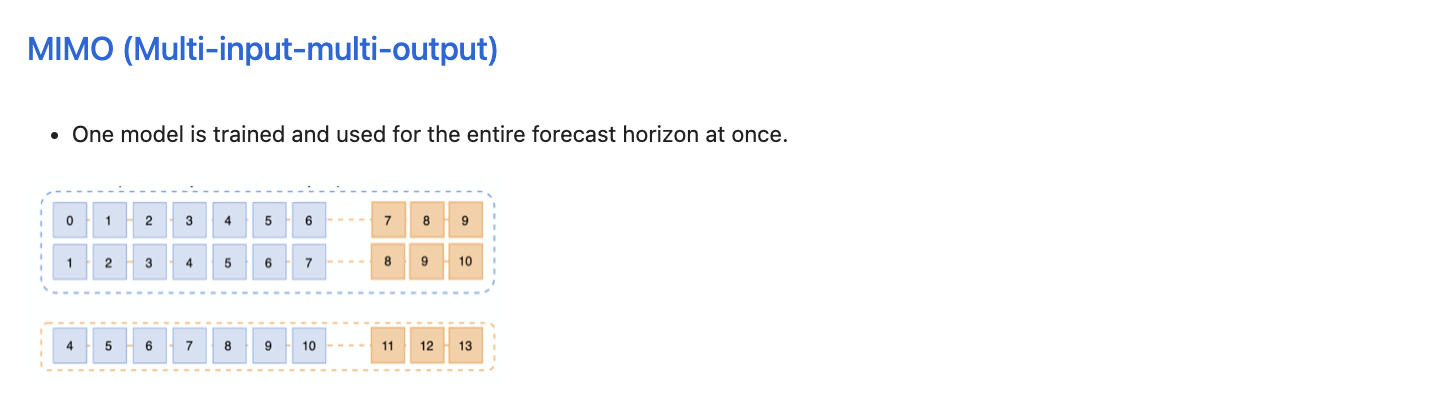

In [22]:
train_df = []
test_df = []
test_targets = []

for current_id in df["id"].unique():
    current_df = df[df["id"] == current_id]
    train_df.append(current_df.iloc[:-HORIZON])
    test_df.append(current_df.iloc[-HORIZON - HISTORY : -HORIZON])
    test_targets.append(current_df.iloc[-HORIZON:])

train_df = pd.concat(train_df)
test_df = pd.concat(test_df)
test_targets = pd.concat(test_targets)

print(f"Train shape: {train_df.shape}")
print(f"Test shape: {test_df.shape}")
print(f"Test targets shape: {test_targets.shape}")

print(f"Number of series in train set: {train_df['id'].nunique()}")
print(f"Number of series in test set: {test_df['id'].nunique()}")
print(f"Number of series in test targets set: {test_targets['id'].nunique()}")

Train shape: (96104, 3)
Test shape: (19032, 3)
Test targets shape: (13176, 3)
Number of series in train set: 366
Number of series in test set: 366
Number of series in test targets set: 366


In [23]:
dataset_params = {
    "target": {"columns": ["value"]},
    "date": {"columns": ["date"]},
    "id": {"columns": ["id"]},
}


train_dataset = TSDataset(
    data=train_df,
    columns_params=dataset_params,
)
test_dataset = TSDataset(
    data=test_df,
    columns_params=dataset_params,
)

INFO:tsururu.dataset.dataset:freq: Month; period: 1.0
                It seems that the data is not regular. Please, check the data and the frequency info.                
                For multivariate regime it is critical to have regular data.
                For global regime each regular part of time series will be processed as separate time series.           
                
INFO:tsururu.dataset.dataset:freq: Month; period: 1.0
                It seems that the data is not regular. Please, check the data and the frequency info.                
                For multivariate regime it is critical to have regular data.
                For global regime each regular part of time series will be processed as separate time series.           
                


In [24]:
# Определим сетку параметров для разных видов препроцессинга
transformers = ["standard_scaler", "difference_normalizer", "last_known_normalizer"]

# Для экономии времени (и так как в ряде есть околонулевые значения) оставим только delta
regimes = ["none", "delta"]

In [25]:
%pip install catboost

In [26]:
results = {}
preds = {}

for transformer in tqdm(transformers):
    for regime in tqdm(regimes):
        print(transformer, regime)
        if transformer == "standard_scaler" and regime != "none":
            continue
        if (transformer == "difference_normalizer" or transformer == "last_known_normalizer") and regime == "none":
            continue

        pipeline_easy_params = {
            "target_lags": HISTORY,
            "date_lags": 1,
            "target_normalizer": transformer,
            "target_normalizer_regime": regime,
            "normalizer_regime": regime,
        }

        # Pipeline отвечает за трансформации временного ряда на всех этапах прогноза от препроцессинга
        # и генерации признаков до Window_normalizing (нормализации на уровне наблюдений для ML моделей)
        # multivariate=False означает, что используем global-modelling (в нашей задаче единственный возможный вариант, т. к. ряды не выровнены)

        # При использовании easy_setup трансформации делаются и на признаки, и на таргеты
        pipeline = Pipeline.easy_setup(
            dataset_params, pipeline_easy_params, multivariate=False
        )
        # Trainer отвечает за обучение модели с использованием inner loop валидации
        trainer = MLTrainer(model=CatBoost, model_params={"task_type": "GPU"}, validator=KFoldCrossValidator)
        # Стратегия отвечает за то, как мы генерируем выборку для предсказания на несколько точек вперед (подробнее на лекции)
        strategy = RecursiveStrategy(horizon=HORIZON, model_horizon=4, history=HISTORY, pipeline=pipeline, trainer=trainer)

        fit_time, _ = strategy.fit(train_dataset)
        forecast_time, current_pred = strategy.predict(test_dataset)

        # Будем использовать метрику MAE (Кстати, какие могут быть проблемы при использовании этой метрики?)
        results[f"{transformer}_{regime}_mae"] = mean_absolute_error(
            test_targets["value"].values, current_pred["value"].values
        )
        preds[f"{transformer}_{regime}_preds"] = current_pred

  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

standard_scaler none


0:	learn: 1.9543770	test: 1.9448643	best: 1.9448643 (0)	total: 77ms	remaining: 1m 16s
1:	learn: 1.9222907	test: 1.9129311	best: 1.9129311 (1)	total: 123ms	remaining: 1m 1s
2:	learn: 1.8914534	test: 1.8823644	best: 1.8823644 (2)	total: 285ms	remaining: 1m 34s
3:	learn: 1.8618509	test: 1.8528010	best: 1.8528010 (3)	total: 513ms	remaining: 2m 7s
4:	learn: 1.8333596	test: 1.8243756	best: 1.8243756 (4)	total: 735ms	remaining: 2m 26s
5:	learn: 1.8058174	test: 1.7968561	best: 1.7968561 (5)	total: 1.04s	remaining: 2m 53s
6:	learn: 1.7793237	test: 1.7703884	best: 1.7703884 (6)	total: 1.23s	remaining: 2m 54s
7:	learn: 1.7538051	test: 1.7447632	best: 1.7447632 (7)	total: 1.44s	remaining: 2m 58s
8:	learn: 1.7294787	test: 1.7203664	best: 1.7203664 (8)	total: 1.5s	remaining: 2m 45s
9:	learn: 1.7059713	test: 1.6968141	best: 1.6968141 (9)	total: 1.54s	remaining: 2m 32s
10:	learn: 1.6833990	test: 1.6742467	best: 1.6742467 (10)	total: 1.58s	remaining: 2m 22s
11:	learn: 1.6613303	test: 1.6523637	best: 1.

INFO:tsururu.model_training.trainer:Fold 0. Score: 0.9396889138499178


...

INFO:tsururu.model_training.trainer:Fold 1. Score: 12737.40823518091


bestTest = 12737.40824
bestIteration = 994
Shrink model to first 995 iterations.
0:	learn: 27527.3975873	test: 29014.2263991	best: 29014.2263991 (0)	total: 7.67ms	remaining: 7.66s
1:	learn: 27082.2077110	test: 28522.2355747	best: 28522.2355747 (1)	total: 13.7ms	remaining: 6.82s
2:	learn: 26659.6175029	test: 28077.0716833	best: 28077.0716833 (2)	total: 19.9ms	remaining: 6.61s
3:	learn: 26248.9075938	test: 27633.0601217	best: 27633.0601217 (3)	total: 25.9ms	remaining: 6.46s
4:	learn: 25887.4345650	test: 27268.0575785	best: 27268.0575785 (4)	total: 31.9ms	remaining: 6.34s
5:	learn: 25508.8596586	test: 26856.3420677	best: 26856.3420677 (5)	total: 37.9ms	remaining: 6.28s
6:	learn: 25154.8304609	test: 26493.5825720	best: 26493.5825720 (6)	total: 44.1ms	remaining: 6.26s
7:	learn: 24788.6400169	test: 26106.2003650	best: 26106.2003650 (7)	total: 50.1ms	remaining: 6.21s
8:	learn: 24439.4859615	test: 25721.3429488	best: 25721.3429488 (8)	total: 56.2ms	remaining: 6.19s
9:	learn: 24096.1511476	test

INFO:tsururu.model_training.trainer:Fold 2. Score: 12869.307607163264
INFO:tsururu.model_training.trainer:Mean score: 12587.0932
INFO:tsururu.model_training.trainer:Std: 310.5487


988:	learn: 6534.4880257	test: 12879.2883029	best: 12879.2883029 (988)	total: 7.1s	remaining: 79ms
989:	learn: 6529.7960590	test: 12880.7474108	best: 12879.2883029 (988)	total: 7.12s	remaining: 71.9ms
990:	learn: 6526.6026354	test: 12880.4850166	best: 12879.2883029 (988)	total: 7.12s	remaining: 64.7ms
991:	learn: 6524.3999039	test: 12879.2203867	best: 12879.2203867 (991)	total: 7.13s	remaining: 57.5ms
992:	learn: 6520.7147285	test: 12877.9074030	best: 12877.9074030 (992)	total: 7.14s	remaining: 50.3ms
993:	learn: 6517.8382617	test: 12877.8527427	best: 12877.8527427 (993)	total: 7.14s	remaining: 43.1ms
994:	learn: 6515.1801775	test: 12876.7084400	best: 12876.7084400 (994)	total: 7.15s	remaining: 35.9ms
995:	learn: 6512.8337212	test: 12876.0817836	best: 12876.0817836 (995)	total: 7.16s	remaining: 28.7ms
996:	learn: 6510.8536819	test: 12874.9099871	best: 12874.9099871 (996)	total: 7.16s	remaining: 21.6ms
997:	learn: 6507.5775952	test: 12872.7124303	best: 12872.7124303 (997)	total: 7.17s	r

INFO:tsururu.dataset.dataset:freq: Month; period: 1.0
                It seems that the data is not regular. Please, check the data and the frequency info.                
                For multivariate regime it is critical to have regular data.
                For global regime each regular part of time series will be processed as separate time series.           
                


In [27]:
res_df = pd.DataFrame.from_dict(results, orient="index", columns=["MAE"])
res_df

,MAE
standard_scaler_none_mae,4337.318238
difference_normalizer_delta_mae,3764.420714
last_known_normalizer_delta_mae,4038.424210


__Нарисуем предсказания для лучшего кейса.__

In [28]:
analyze_predictions(train_df, test_targets, preds[f"difference_normalizer_delta_preds"], last_points=50)

random 10 mae: 1169.2077653247227


# DL Supervised: DLinear

__Давайте попробуем перейти от ML к DL и посмотреть, как работают DLinear.__

`DLinear` — это простая и быстрая модель, которая выделяет тренд на основе AveragePooling, а затем на компонентах тренда и остатков применяет nn.Linear и собирает всё обратно.

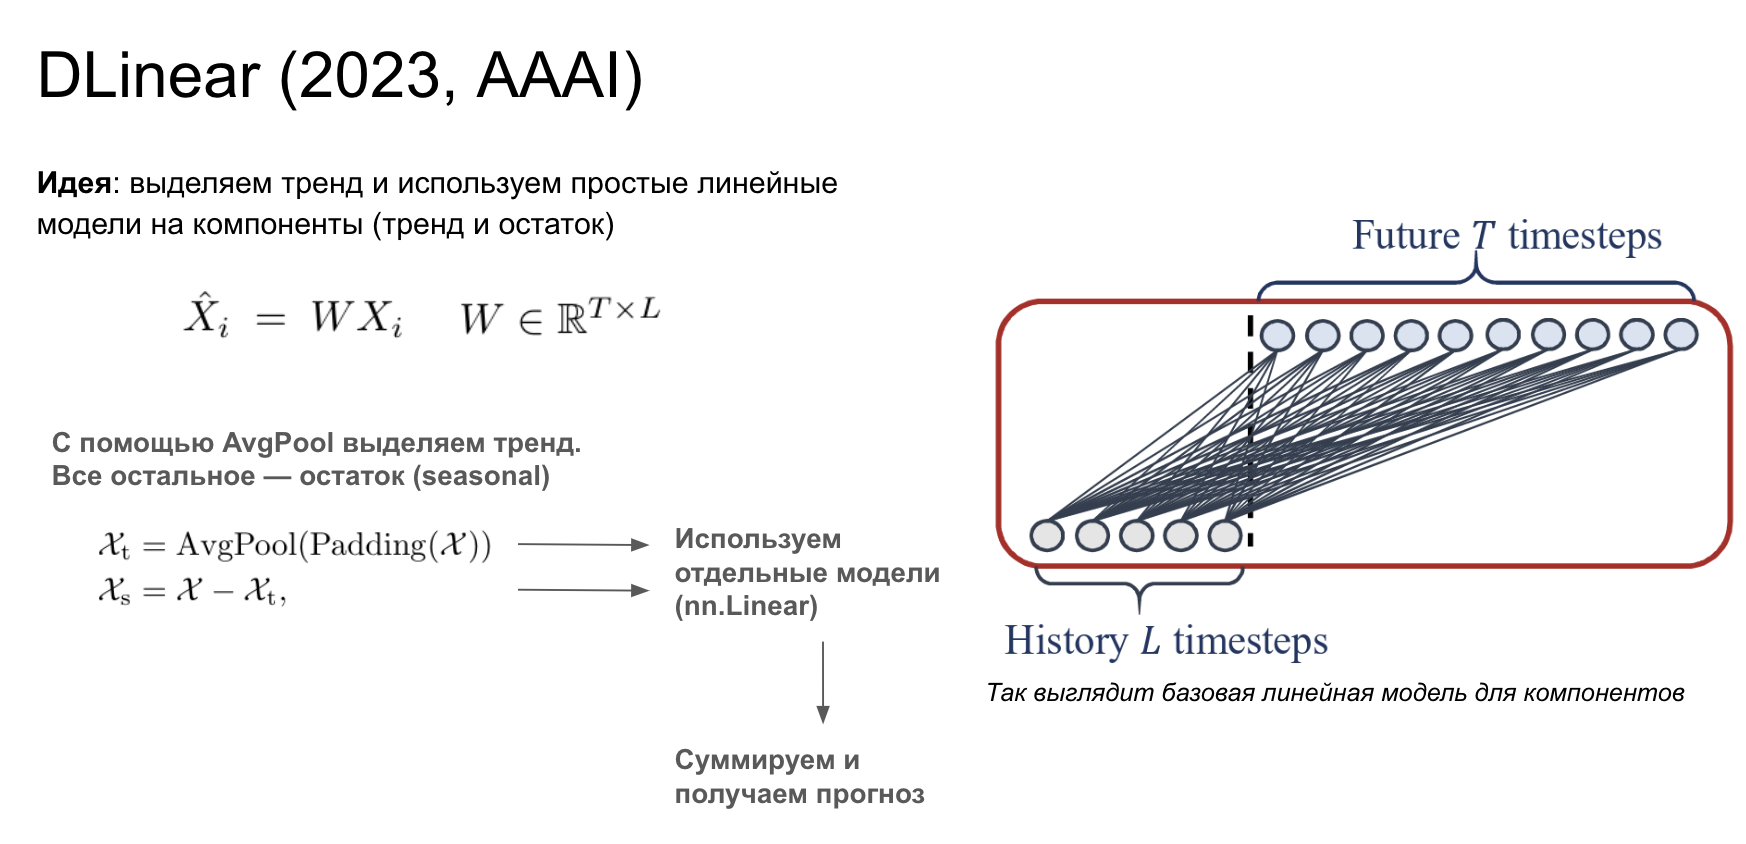

In [54]:
class moving_avg(Module):
    """Moving average block to highlight the trend of time series.

    Args:
        kernel_size: size of the kernel.
        stride: stride for the moving average.

    """

    def __init__(self, kernel_size: int, stride: int):
        super(moving_avg, self).__init__()
        self.kernel_size = kernel_size
        self.avg = nn.AvgPool1d(kernel_size=kernel_size, stride=stride, padding=0)

    def forward(self, x: "torch.Tensor") -> "torch.Tensor":
        """Forward pass for computing the moving average.

        Args:
            x: input tensor.

        Returns:
            tensor with the moving average applied.

        """
        # padding on the both ends of time series
        front = x[:, 0:1, :].repeat(1, (self.kernel_size - 1) // 2, 1)
        end = x[:, -1:, :].repeat(1, self.kernel_size - 1 - (self.kernel_size - 1) // 2, 1)
        x = torch.cat([front, x, end], dim=1)

        # apply moving average (among the time series dimension)
        x = self.avg(x.permute(0, 2, 1))
        x = x.permute(0, 2, 1)

        return x


class series_decomp(Module):
    """Series decomposition block.

    Args:
        kernel_size: size of the kernel for the moving average.

    """

    def __init__(self, kernel_size: int):
        super(series_decomp, self).__init__()
        self.moving_avg = moving_avg(kernel_size, stride=1)

    def forward(self, x: "torch.Tensor") -> tuple["torch.Tensor", "torch.Tensor"]:
        """Forward pass for decomposing the series into trend and remainder.

        Args:
            x: input tensor.

        Returns:
            tuple of tensors (remainder, trend).

        """
        moving_mean = self.moving_avg(x)
        res = x - moving_mean

        return res, moving_mean


class DLinear_NN(Module):
    """DLInear model from the paper https://arxiv.org/pdf/2205.13504.pdf.

    Args:
        - seq_len: int, the length of the input sequence.
        - pred_len: int, the length of the output sequence.
        - moving_avg: int, the size of the moving average window.

    """

    def __init__(
        self,
        seq_len: int,
        pred_len: int,
        moving_avg: int = 25,
    ):
        super(DLinear_NN, self).__init__()
        # Params from model_params
        self.seq_len = seq_len["series"]
        self.pred_len = pred_len

        # Decomposition
        self.decompsition = series_decomp(moving_avg)

        # Linear layers
        self.Linear_Seasonal = nn.Linear(self.seq_len, self.pred_len)
        self.Linear_Trend = nn.Linear(self.seq_len, self.pred_len)

        # Linear layers initialization
        self.Linear_Seasonal.weight = nn.Parameter(
            (1 / self.seq_len) * torch.ones([self.pred_len, self.seq_len])
        )
        self.Linear_Trend.weight = nn.Parameter(
            (1 / self.seq_len) * torch.ones([self.pred_len, self.seq_len])
        )

    def forward(self, x: "torch.Tensor") -> "torch.Tensor":
        """Forward pass of the model.

        Args:
            x: input tensor of shape (batch_size, seq_len, num_features).

        Returns:
            Encoded tensor of shape (batch_size, pred_len, num_features).

        """
        # Делаем декомпозицию временного ряда на тренд и остаток (seasonal)
        seasonal_init, trend_init = self.decompsition(x)

        # Транспонируем тензоры, чтобы они были в формате (batch_size, num_features, seq_len)
        seasonal_init, trend_init = seasonal_init.permute(0, 2, 1), trend_init.permute(0, 2, 1)

        # Применяем линейные слои к тренду и остаткам
        seasonal_output = self.Linear_Seasonal(seasonal_init)
        trend_output = self.Linear_Trend(trend_init)

        # Складываем выходы линейных слоев
        x = seasonal_output + trend_output

        # Транспонируем обратно в формат (batch_size, seq_len, num_features)
        x = x.permute(0, 2, 1)

        return x[:, -self.pred_len :, :]

Выделим явно валидационную выборку.

In [55]:
train_df = []
val_df = []
test_df = []
test_targets = []
for current_id in df["id"].unique():
    current_df = df[df["id"] == current_id]
    train_df.append(current_df.iloc[:-2 * HORIZON])
    val_df.append(current_df.iloc[-2 * HORIZON - HISTORY : -HORIZON])
    test_df.append(current_df.iloc[-HORIZON - HISTORY:-HORIZON])
    test_targets.append(current_df.iloc[-HORIZON:])
train_df = pd.concat(train_df)
val_df = pd.concat(val_df)
test_df = pd.concat(test_df)
test_targets = pd.concat(test_targets)

print(f"Train shape: {train_df.shape}")
print(f"Val shape: {val_df.shape}")
print(f"Test shape: {test_df.shape}")
print(f"Test targets shape: {test_targets.shape}")

print(f"Number of series in train set: {train_df['id'].nunique()}")
print(f"Number of series in val set: {val_df['id'].nunique()}")
print(f"Number of series in test set: {test_df['id'].nunique()}")
print(f"Number of series in test targets set: {test_targets['id'].nunique()}")

Train shape: (82928, 3)
Val shape: (32175, 3)
Test shape: (19032, 3)
Test targets shape: (13176, 3)
Number of series in train set: 366
Number of series in val set: 366
Number of series in test set: 366
Number of series in test targets set: 366


In [56]:
seed_everything()
dataset_params = {
    "target": {
        "columns": ["value"],
        "type": "continuous",
    },
    "date": {
        "columns": ["date"],
        "type": "datetime",
    },
    "id": {
        "columns": ["id"],
        "type": "categorical",
    }
}

train_dataset = TSDataset(
    data=train_df,
    columns_params=dataset_params,
    print_freq_period_info=True,
)
val_dataset = TSDataset(
    data=val_df,
    columns_params=dataset_params,
    print_freq_period_info=False,
)
test_dataset = TSDataset(
    data=test_df,
    columns_params=dataset_params,
    print_freq_period_info=False,
)

INFO:tsururu.dataset.dataset:freq: Month; period: 1.0
                It seems that the data is not regular. Please, check the data and the frequency info.                
                For multivariate regime it is critical to have regular data.
                For global regime each regular part of time series will be processed as separate time series.           
                
                It seems that the data is not regular. Please, check the data and the frequency info.                
                For multivariate regime it is critical to have regular data.
                For global regime each regular part of time series will be processed as separate time series.           
                
                It seems that the data is not regular. Please, check the data and the frequency info.                
                For multivariate regime it is critical to have regular data.
                For global regime each regular part of time series will be processed 

In [57]:
pipeline_params = {
    "target": {
        "columns": ["value"],
        "features": {
            "DifferenceNormalizer": {
                    "regime": "delta",
                    "transform_target": True,  # Видим параметры, которые отвечают за раздельное применение
                    "transform_features": True,  # трансформеров к признакам и таргетам
                },
            "MissingValuesImputer": {  # После DifferenceNormalizer у нас неизбежно появляются NaN в данных (в первом значении каждого сегмента)
                "constant_value": 0,  # Заполним нулями
                "transform_target": True,
                "transform_features": True,
            },
            "StandardScalerTransformer": {  # И выровним значения рядов прежде чем подавать в DL модель
                "transform_target": True,
                "transform_features": True,
                "agg_by_id": True,
            },
            "LagTransformer": {"lags": HISTORY},
        },
    }
}

In [58]:
pipeline = Pipeline.from_dict(pipeline_params, multivariate=False)

validation = HoldOutValidator
validation_params = {
    "validation_data": val_dataset
}

trainer_params = {
    "device": DEVICE,
    "num_workers": 4,
    "best_by_metric": True,
    "save_to_dir": False,
    "batch_size": 128,
    "n_epochs": 5,
    "early_stopping_patience": 2,
}


# Configure the model and validation parameters
trainer = DLTrainer(
    model=DLinear_NN,
    model_params={},
    validator=validation,
    validation_params=validation_params,
    **trainer_params,
)

strategy = RecursiveStrategy(horizon=HORIZON, model_horizon=4, history=HISTORY, pipeline=pipeline, trainer=trainer)

fit_time, _ = strategy.fit(train_dataset)
forecast_time, current_pred = strategy.predict(test_dataset)

INFO:tsururu.model_training.trainer:length of train dataset: 62834
INFO:tsururu.model_training.trainer:length of val dataset: 12045
INFO:tsururu.model_training.trainer:Epoch 1/5, cost time: 121.76s
INFO:tsururu.model_training.trainer:train loss: 0.6815
INFO:tsururu.model_training.trainer:Validation, Loss: 1.7692, Metric: -1.7692
INFO:tsururu.model_training.trainer:val loss: 1.7692, val metric: -1.7692
INFO:tsururu.model_training.trainer:Epoch 2/5, cost time: 124.99s
INFO:tsururu.model_training.trainer:train loss: 0.5807
INFO:tsururu.model_training.trainer:Validation, Loss: 1.7587, Metric: -1.7587
INFO:tsururu.model_training.trainer:val loss: 1.7587, val metric: -1.7587
INFO:tsururu.model_training.trainer:Epoch 3/5, cost time: 122.32s
INFO:tsururu.model_training.trainer:train loss: 0.5764
INFO:tsururu.model_training.trainer:Validation, Loss: 1.7596, Metric: -1.7596
INFO:tsururu.model_training.trainer:val loss: 1.7596, val metric: -1.7596
INFO:tsururu.model_training.torch_based.callbacks

Несколько раз вывели размер теста (а именно 9 раз), так как модель 9 раз авторегрессионно предсказывала model_horizon точек. 36 // 4 = 9

In [59]:
analyze_predictions(train_df, test_targets, current_pred, last_points=50)

random 10 mae: 1450.7602613776737


# DL Zero-shot: Chronos

__Наконец, подойдем к краю науки и разберем разницу между Supervised и Zero-shot подходами к предсказанию.__

Прелесть Zero-shot подходов заключается в том, что они позволяют нам предсказывать временные ряды без обучения модели. Это может быть полезно, если у нас слишком мало данных, чтобы нормально обучить модель или если у нас слишком мало времени и нужно очень быстро получить какой-то бейзлайн.

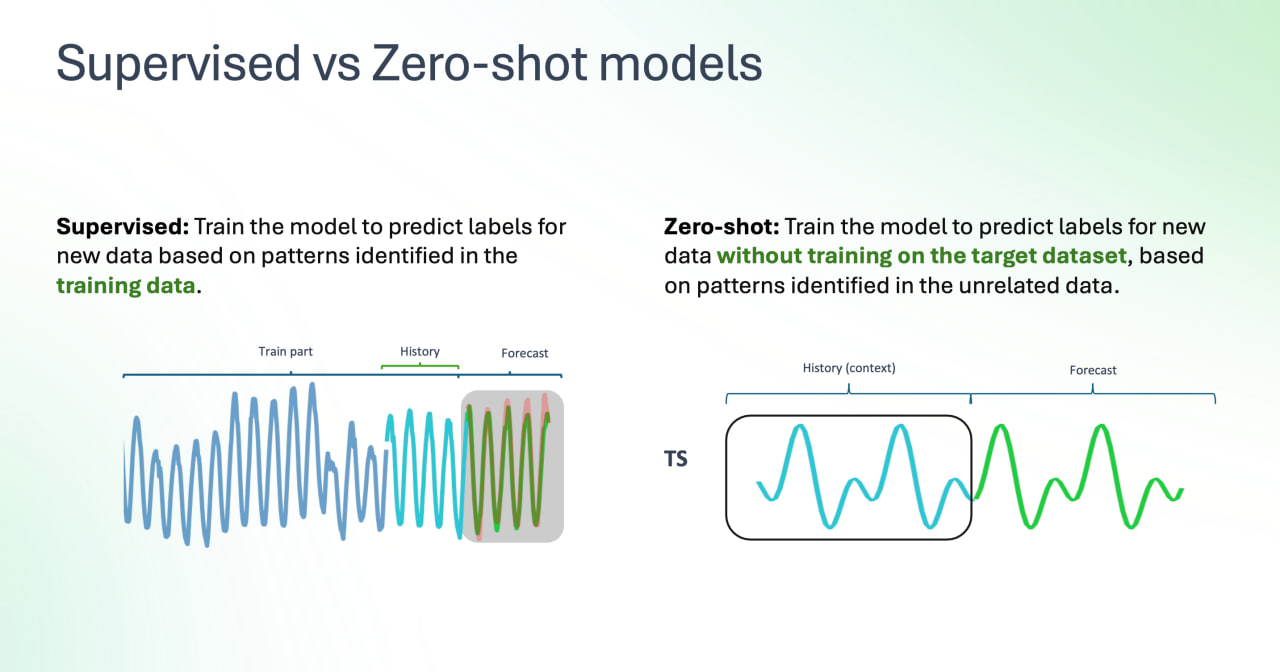

`Chronos` — это модель, которая использует предобученные трансформеры для предсказания временных рядов без дополнительной настройки.

Статья: https://arxiv.org/pdf/2403.07815

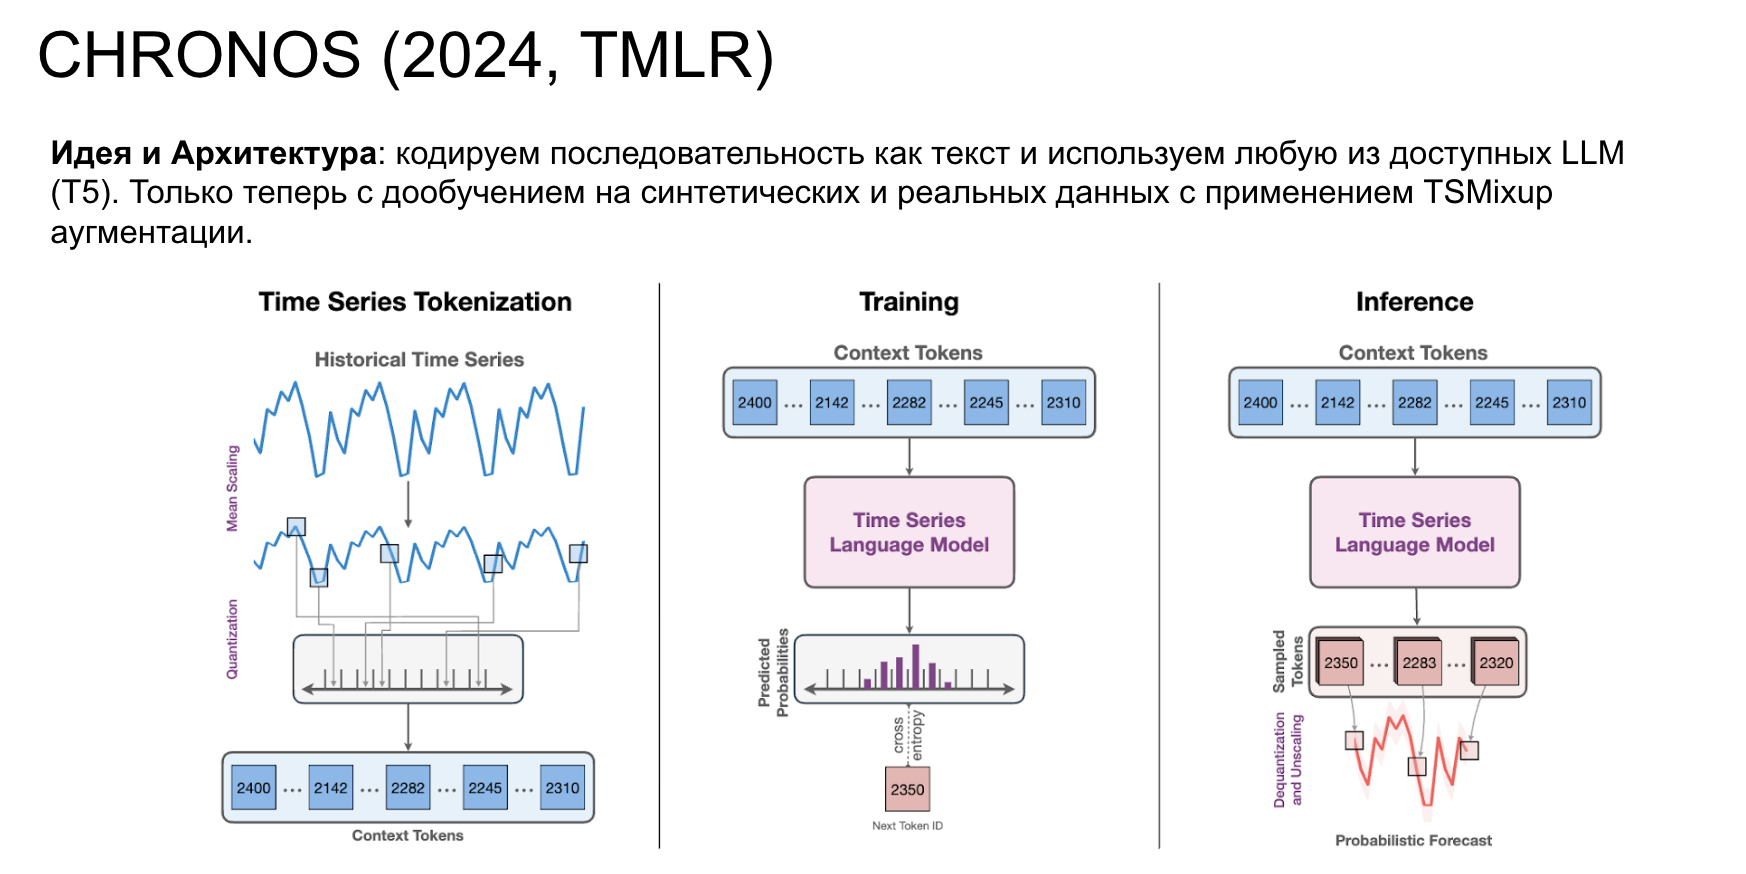

In [62]:
seed_everything()
# Загрузим предобученную модель Chronos-Bolt
pipeline = BaseChronosPipeline.from_pretrained(
    "amazon/chronos-bolt-small",
    device_map="cuda",
)

# Сделаем предсказание на тестовой выборке
test_preds = test_targets.copy()
test_preds.loc[:, 'value'] =  0

# Chronos — local модель, то есть на каждый ряд мы делаем предсказание отдельно
for current_id in tqdm(test_targets['id'].unique()):
    current_df = df[df["id"] == current_id]

    # В контекст передаем все точки, кроме последних HORIZON
    context = current_df.iloc[:-1 * HORIZON]

    pred = pipeline.predict(
        torch.tensor(context["value"].values.flatten().astype(float)),
        prediction_length=HORIZON
    ).numpy()[0,  :]
    # Chronos выдает распределение предсказаний, поэтому мы берем медиану
    # (можно использовать и другие статистики, например, какую-нибудь квантиль)
    pred = np.median(pred, axis=0)

    # Заполняем предсказания в тестовой выборке
    test_preds.loc[test_preds["id"] == current_id, 'value'] = pred

  0%|          | 0/366 [00:00<?, ?it/s]

In [63]:
analyze_predictions(train_df, test_targets, test_preds, last_points=50)

random 10 mae: 1405.1669307380253


__Что можно сказать про результаты zero-shot предсказаний? (помним, что модель вообще не обучалась на наших данных!)__